# IPDA – Assignment 2: Petrol prices & forecasts
The structure follows the professor's Assignment 2 (slides 42–43): price download, forecast download, "Prices" part, "Forecasts" part.

**Important (slide 41):** do not share the API keys and do not upload prices/forecasts to the internet. Credentials are read from environment variables, never hard-coded.

## 0. Configuration (change only here)

In [1]:
import os, glob, datetime as dt
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

# --- Time range (slide 42: must be easy to change) ---
START = "2026-05-01"
END   = "2026-09-30"

# --- Paths ---
# Cloned tankerkoenig folder (contains prices/ and stations/)
TANKER_DIR    = r"tankerkoenig-data"
# Forecast CSV snapshots from ILIAS; a Parquet cache is created on first run
FORECAST_DIR   = Path(r"data/forecasts/Petrolforecastscsv")
FORECAST_CACHE = Path(r"data/forecasts/fuel_forecasts.parquet")

# --- Fuels: tankerkoenig column -> name used in the assignment ---
FUELS = {"e10": "Super E10", "diesel": "Diesel"}   # "Truck Diesel": see section 1

# --- The 4 stations of the assignment (slide 43) ---
STATIONS = {
    "HEM":   dict(street="Am Hartweg",         post_code="44149", city="Dortmund"),
    "STAR":  dict(street="Hebewerkstr",        post_code="44581", city="Castrop-Rauxel"),
    "SHELL": dict(street="Hebewerkstr",        post_code="44581", city="Castrop-Rauxel"),
    "ARAL":  dict(street="Lütgendortmunder",   post_code="44892", city="Bochum"),
}
# Impossible prices (9.99 EUR; 0.01 EUR ...)
MIN_OK, MAX_OK = 0.80, 4.00

## 1. Price download (tankerkoenig)
Slide 35: use a **git clone of the CSV files** (not the API). Register at tankerkoenig.de for access. In a terminal (once), with your own credentials:

```
git clone https://<USER>:<TOKEN>@dev.azure.com/tankerkoenig/_git/tankerkoenig-data
```
(the exact address and credentials are in the `readme.md` on the website). Do not put credentials in the notebook.

A price is reported only when it changes; if a station has no change, the previous day's price is still valid (slide 35). So we build a step series below.

In [2]:
days = pd.date_range(START, END, freq="D")

def read_day(kind, d):
    p = os.path.join(TANKER_DIR, kind, f"{d:%Y}", f"{d:%m}", f"{d:%Y-%m-%d}-{kind}.csv")
    return pd.read_csv(p) if os.path.exists(p) else None

# 1) Find the UUIDs of the 4 stations in the stations file (last day of the range)
st = None
for d in reversed(days):
    st = read_day("stations", d)
    if st is not None: break
assert st is not None, "No stations CSV found - check TANKER_DIR"

cand = {}
for key, q in STATIONS.items():
    m = st[st.street.str.contains(q["street"], case=False, na=False) &
           (st.post_code.astype(str).str.strip()==q["post_code"])]
    cand[key] = m[["uuid","name","brand","street","house_number","post_code","city","latitude","longitude"]]
    print(f"--- {key}"); display(cand[key])

--- HEM


,uuid,name,brand,street,house_number,post_code,city,latitude,longitude
3880,e1a15081-24dd-9107-e040-0b0a3dfe563c,"Dortmund, Am Hartweg 175",HEM,Am Hartweg,175,44149,Dortmund,51.497066,7.403551


--- STAR


,uuid,name,brand,street,house_number,post_code,city,latitude,longitude
1572,005056ba-7cb6-1ed2-bceb-7966ed5a4d26,star Tankstelle,STAR,Hebewerkstraße,18,44581,Castrop-Rauxel,51.600507,7.313701
11140,86cac7b9-6008-4e6d-9542-f07396ae42bb,Shell Castrop-Rauxel Hebewerkstr. 25,Shell,Hebewerkstr.,25,44581,Castrop-Rauxel,51.601760,7.313718


--- SHELL


,uuid,name,brand,street,house_number,post_code,city,latitude,longitude
1572,005056ba-7cb6-1ed2-bceb-7966ed5a4d26,star Tankstelle,STAR,Hebewerkstraße,18,44581,Castrop-Rauxel,51.600507,7.313701
11140,86cac7b9-6008-4e6d-9542-f07396ae42bb,Shell Castrop-Rauxel Hebewerkstr. 25,Shell,Hebewerkstr.,25,44581,Castrop-Rauxel,51.601760,7.313718


--- ARAL


,uuid,name,brand,street,house_number,post_code,city,latitude,longitude
13875,3bfab341-1f1e-49e0-8c32-bc77ca730e57,Aral Tankstelle,ARAL,Lütgendortmunder Hellweg,200/a.d A40,44892,Bochum,51.494022,7.339435


**Check carefully:** a station can appear several times (different names/coordinates, slide 43). Pick the correct UUID (house numbers: HEM 175, STAR 18, SHELL 25, ARAL = Autobahnraststätte Beverbach) and enter it below.

In [3]:
# Verified using the station table displayed above:
UUIDS = {
    "HEM":   "e1a15081-24dd-9107-e040-0b0a3dfe563c",
    "STAR":  "005056ba-7cb6-1ed2-bceb-7966ed5a4d26",
    "SHELL": "86cac7b9-6008-4e6d-9542-f07396ae42bb",
    "ARAL":  "3bfab341-1f1e-49e0-8c32-bc77ca730e57",
}
assert all(UUIDS.values()), "Fill in UUIDS using the tables above"
uuid2key = {v:k for k,v in UUIDS.items()}

In [4]:
# 2) Load prices day by day, keep ONLY the 4 stations (saves memory)
frames = []
for d in days:
    p = read_day("prices", d)
    if p is None:
        print("missing:", d.date()); continue
    p = p[p.station_uuid.isin(UUIDS.values())]
    frames.append(p)
raw = pd.concat(frames, ignore_index=True)
raw["date"] = pd.to_datetime(raw["date"], utc=True).dt.tz_convert("Europe/Berlin")
raw["station"] = raw.station_uuid.map(uuid2key)

# long format: station, fuel, ts, price
long = raw.melt(id_vars=["date","station"], value_vars=list(FUELS), var_name="fuel", value_name="price")
long = long.rename(columns={"date":"ts"}).dropna(subset=["price"])
long["fuel"] = long.fuel.map(FUELS)
print(long.shape); long.head()

(20996, 4)


,ts,station,fuel,price
0,2026-05-01 00:02:02+02:00,SHELL,Super E10,1.959
1,2026-05-01 00:02:02+02:00,ARAL,Super E10,1.959
2,2026-05-01 00:11:12+02:00,HEM,Super E10,2.029
3,2026-05-01 00:18:18+02:00,STAR,Super E10,1.949
4,2026-05-01 07:34:25+02:00,SHELL,Super E10,1.959


### Truck Diesel
The assignment asks for "Super E10", "Diesel" and "Truck Diesel". The tankerkoenig files I know only have `e5`, `e10`, `diesel`. Check (a) the tankerkoenig `readme.md` for a truck diesel column, and (b) the fuel names in the forecast file (section 3). If a column exists, add it to `FUELS` and everything below works unchanged.

## 1b. Check for erroneous prices

In [5]:
bad = long[(long.price < MIN_OK) | (long.price > MAX_OK)]
print("Suspicious prices:", len(bad), "of", len(long))
display(bad.groupby(["station","fuel"]).price.describe())
display(bad.head(20))
# drop erroneous prices
clean = long.drop(bad.index).sort_values(["station","fuel","ts"]).reset_index(drop=True)
# drop consecutive repeats of the same price
clean = clean[clean.groupby(["station","fuel"]).price.diff().fillna(1) != 0].reset_index(drop=True)
clean.groupby(["station","fuel"]).size().unstack()

Suspicious prices: 0 of 20996


,count,mean,std,min,25%,50%,75%,max


,ts,station,fuel,price


fuel,Diesel,Super E10
station,,
ARAL,1885,1782
HEM,2288,2319
SHELL,1643,1518
STAR,1742,1618


## 2. Assignment "Prices": daily / weekly patterns
Rule from slide 33: **since 2026-04-01 prices may only be raised at 12:00; they can be lowered at any time.** So we expect a jump up at 12:00 and declines during the day.

In [6]:
# Step series -> 5-minute grid (price holds until the next change)
grid = pd.date_range(pd.Timestamp(START, tz="Europe/Berlin"),
                     pd.Timestamp(END, tz="Europe/Berlin")+pd.Timedelta(days=1),
                     freq="5min", inclusive="left")
def to_grid(g):
    s = g.set_index("ts").price
    s = s[~s.index.duplicated(keep="last")]
    return s.reindex(s.index.union(grid)).ffill().reindex(grid)

step = (pd.concat({key: to_grid(g) for key, g in clean.groupby(["station", "fuel"])},
                  names=["station", "fuel", "ts"])
          .rename("price").reset_index())
step["hour"] = step.ts.dt.hour; step["dow"] = step.ts.dt.dayofweek
step["date"] = step.ts.dt.date; step["month"] = step.ts.dt.to_period("M")
step.head()

/tmp/ipykernel_1783205/2221242444.py:3: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  pd.Timestamp(END, tz="Europe/Berlin")+pd.Timedelta(days=1),
/tmp/ipykernel_1783205/2221242444.py:14: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  step["date"] = step.ts.dt.date; step["month"] = step.ts.dt.to_period("M")


,station,fuel,ts,price,hour,dow,date,month
0,ARAL,Diesel,2026-05-01 00:00:00+02:00,NaN,0,4,2026-05-01,2026-05
1,ARAL,Diesel,2026-05-01 00:05:00+02:00,2.059,0,4,2026-05-01,2026-05
2,ARAL,Diesel,2026-05-01 00:10:00+02:00,2.059,0,4,2026-05-01,2026-05
3,ARAL,Diesel,2026-05-01 00:15:00+02:00,2.059,0,4,2026-05-01,2026-05
4,ARAL,Diesel,2026-05-01 00:20:00+02:00,2.059,0,4,2026-05-01,2026-05


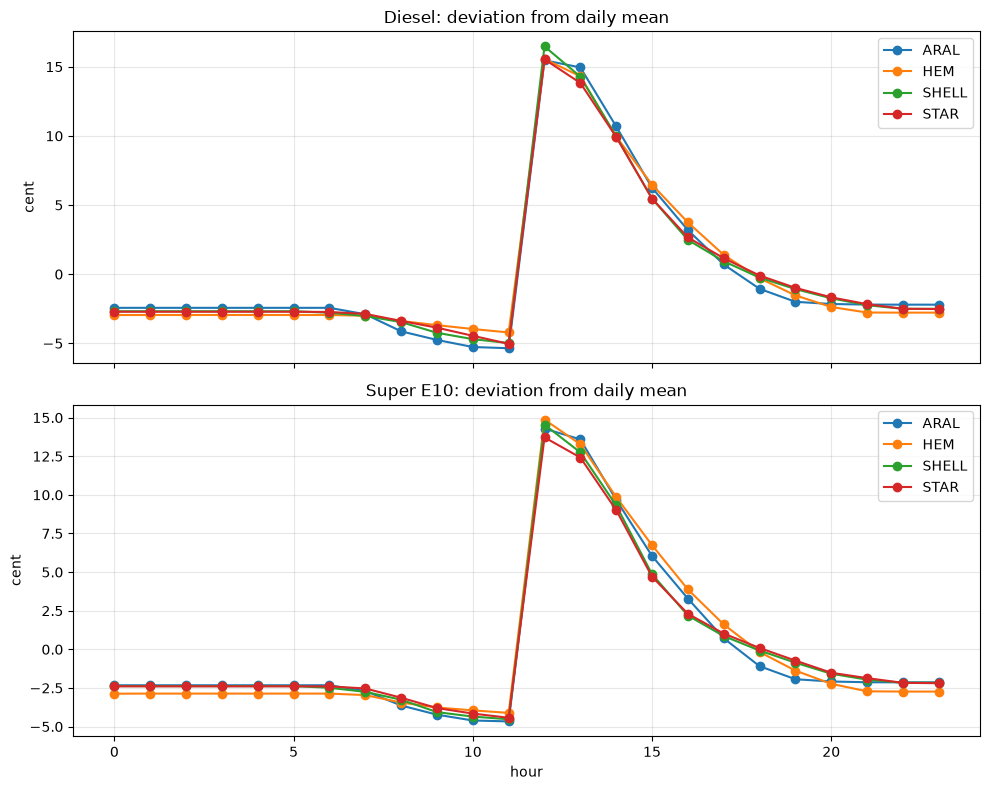

In [7]:
# A) Daily profile: deviation from the daily mean price by hour (in cents)
step["dev_day"] = step.price - step.groupby(["station","fuel","date"]).price.transform("mean")
daily = step.groupby(["station","fuel","hour"]).dev_day.mean().mul(100).rename("cent").reset_index()
fig, axs = plt.subplots(len(FUELS), 1, figsize=(10, 4*len(FUELS)), sharex=True)
for ax, (f, g) in zip(np.atleast_1d(axs), daily.groupby("fuel")):
    for s, gg in g.groupby("station"): ax.plot(gg.hour, gg.cent, marker="o", label=s)
    ax.set_title(f"{f}: deviation from daily mean"); ax.set_ylabel("cent"); ax.legend(); ax.grid(alpha=.3)
plt.xlabel("hour"); plt.tight_layout(); plt.show()

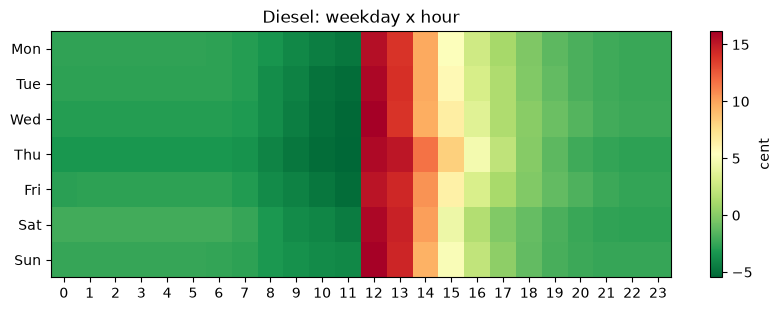

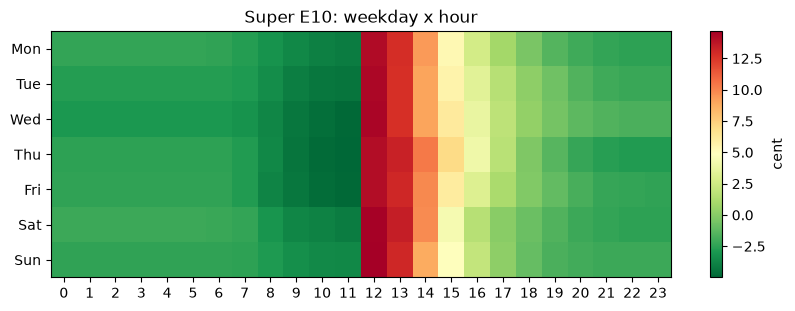

Super E10 MIN: (np.int32(3), np.int32(11)) -5.0 c | MAX: (np.int32(6), np.int32(12)) 14.7 c
Diesel MIN: (np.int32(3), np.int32(11)) -5.5 c | MAX: (np.int32(2), np.int32(12)) 16.2 c


In [8]:
# B) Weekly profile: weekday x hour heatmap per fuel (mean of the 4 stations)
for f, g in step.groupby("fuel"):
    h = g.groupby(["dow","hour"]).dev_day.mean().mul(100).unstack()
    plt.figure(figsize=(10,3.2)); plt.imshow(h, aspect="auto", cmap="RdYlGn_r")
    plt.yticks(range(7), ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]); plt.xticks(range(24))
    plt.colorbar(label="cent"); plt.title(f"{f}: weekday x hour"); plt.show()
# When are prices lowest / highest?
w = step.groupby(["fuel","dow","hour"]).dev_day.mean().mul(100)
for f in FUELS.values():
    print(f, "MIN:", w[f].idxmin(), round(w[f].min(),1), "c | MAX:", w[f].idxmax(), round(w[f].max(),1), "c")

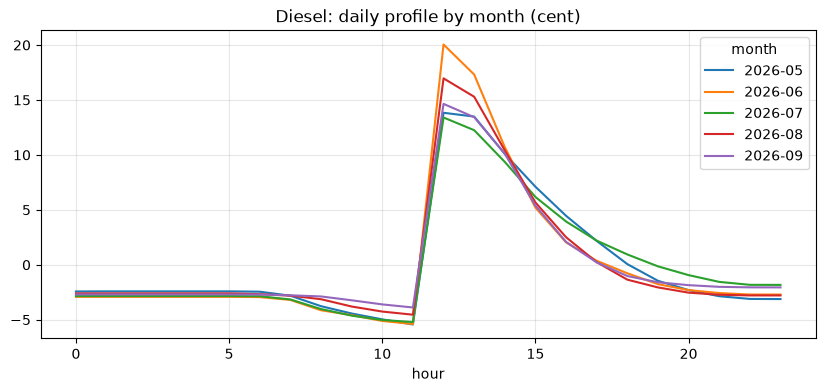

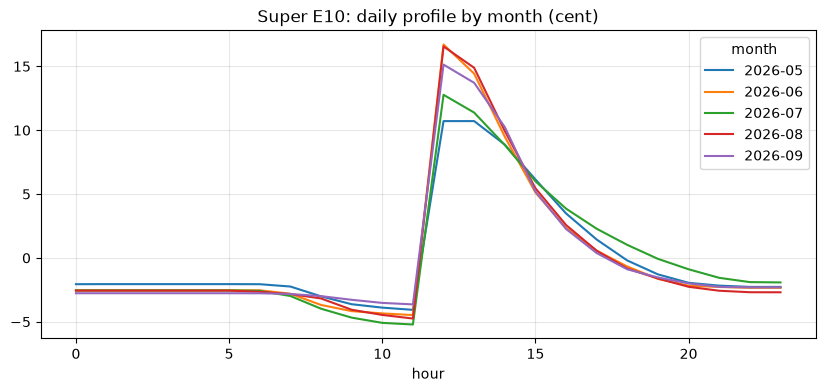

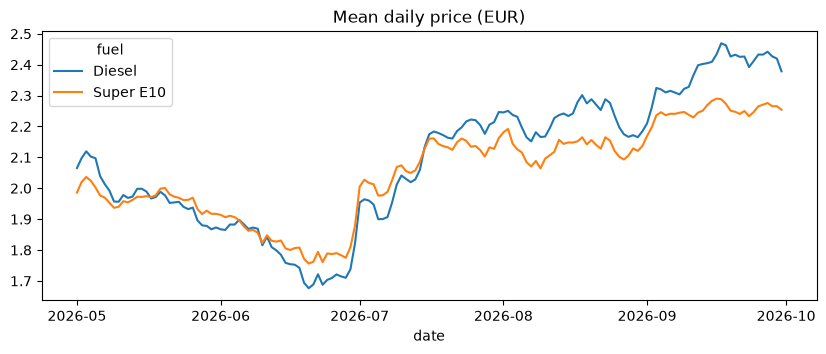

In [9]:
# C) Are the patterns constant or do they change? Daily profile by month
for f, g in step.groupby("fuel"):
    p = g.groupby(["month","hour"]).dev_day.mean().mul(100).unstack(0)
    p.plot(figsize=(10,4), title=f"{f}: daily profile by month (cent)"); plt.grid(alpha=.3); plt.show()
# Mean daily price over time
step.groupby(["fuel","date"]).price.mean().unstack(0).plot(figsize=(10,3.5), title="Mean daily price (EUR)"); plt.show()

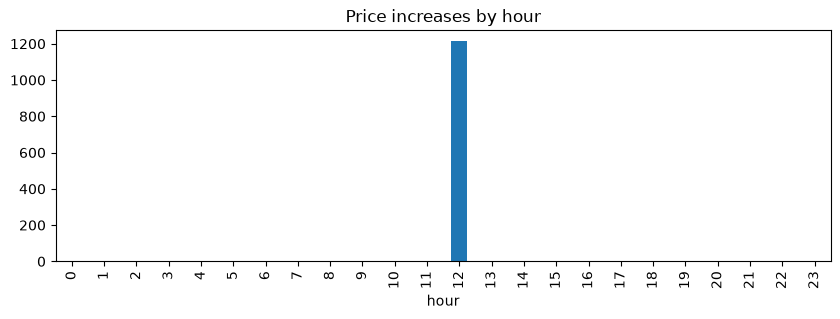

In [10]:
# D) Number of price increases by hour (checks the 12:00 rule)
chg = clean.copy(); chg["up"] = chg.groupby(["station","fuel"]).price.diff() > 0
chg["hour"] = chg.ts.dt.hour
chg[chg.up].groupby("hour").size().reindex(range(24), fill_value=0).plot.bar(figsize=(10,3), title="Price increases by hour"); plt.show()

### Bonus: public and school holidays (NRW)

In [11]:
try:
    import holidays
    pub = set(holidays.Germany(subdiv="NW", years=range(pd.Timestamp(START).year, pd.Timestamp(END).year+1)).keys())
except Exception:
    pub = {dt.date(2026,5,1), dt.date(2026,5,14), dt.date(2026,5,25), dt.date(2026,6,4)}  # please verify!
# NRW summer holidays 2026 (VERIFY on schulferien.org before submitting)
school = [(dt.date(2026,7,20), dt.date(2026,9,1))]
isschool = lambda d: any(a<=d<=b for a,b in school)
step["public"] = step.date.isin(pub); step["school"] = step.date.map(isschool)
step["weekday_type"] = np.where(step.dow>=5, "weekend", "weekday")
# mean daily price by day type
dd = step.groupby(["fuel","date"]).agg(price=("price","mean"), public=("public","first"),
        school=("school","first"), wd=("weekday_type","first")).reset_index()
display(dd.groupby(["fuel","wd","public"]).price.mean().unstack())
display(dd.groupby(["fuel","wd","school"]).price.mean().unstack())

public                False     True 
fuel      wd                         
Diesel    weekday  2.098122  1.969557
          weekend  2.088494       NaN
Super E10 weekday  2.058526  1.956863
          weekend  2.048743       NaN

school                False     True 
fuel      wd                         
Diesel    weekday  2.042916  2.214892
          weekend  2.039191  2.219971
Super E10 weekday  2.023453  2.130214
          weekend  2.015919  2.136274

## 3. Forecast download (ILIAS)
The file has the columns: `station_id, fuel, unit, target_ts_berlin, retrieved_at_berlin, price, min_price, max_price` (target = the forecasted moment, retrieved = when the forecast was fetched).

In [12]:
if FORECAST_CACHE.exists():
    fc = pd.read_parquet(FORECAST_CACHE)
else:
    forecast_files = sorted(FORECAST_DIR.glob("forecast_*.csv"))
    assert forecast_files, f"No forecast CSV files found in {FORECAST_DIR}"
    fc = pd.concat((pd.read_csv(p) for p in forecast_files), ignore_index=True)
    for c in ["target_ts_berlin", "retrieved_at_berlin"]:
        fc[c] = pd.to_datetime(fc[c], utc=True).dt.tz_convert("Europe/Berlin")
    FORECAST_CACHE.parent.mkdir(parents=True, exist_ok=True)
    fc.to_parquet(FORECAST_CACHE, index=False)
print(fc.shape); display(fc.head())
print(fc.fuel.unique(), fc.unit.unique(), fc.station_id.unique())

(1558652, 8)


,station_id,fuel,unit,target_ts_berlin,retrieved_at_berlin,price,min_price,max_price
0,005056ba-7cb6-1ed2-bceb-7966ed5a4d26,Diesel,Liter,2026-08-05 11:00:00+02:00,2026-08-05 10:50:00.004026+02:00,2.184,2.182,2.345
1,005056ba-7cb6-1ed2-bceb-7966ed5a4d26,LPG,Liter,2026-08-05 11:00:00+02:00,2026-08-05 10:50:00.004026+02:00,1.061,1.057,1.064
2,005056ba-7cb6-1ed2-bceb-7966ed5a4d26,SuperE10,Liter,2026-08-05 11:00:00+02:00,2026-08-05 10:50:00.004026+02:00,2.077,2.074,2.262
3,005056ba-7cb6-1ed2-bceb-7966ed5a4d26,SuperE5,Liter,2026-08-05 11:00:00+02:00,2026-08-05 10:50:00.004026+02:00,2.137,2.134,2.322
4,005056ba-7cb6-1ed2-bceb-7966ed5a4d26,SuperE5P,Liter,2026-08-05 11:00:00+02:00,2026-08-05 10:50:00.004026+02:00,2.250,2.243,2.257


['Diesel' 'LPG' 'SuperE10' 'SuperE5' 'SuperE5P' 'TruckDiesel'
 'AdBlueTruck' 'DieselP' 'Super100' 'Super98' 'Super98P'] ['Liter'] ['005056ba-7cb6-1ed2-bceb-7966ed5a4d26'
 '3bfab341-1f1e-49e0-8c32-bc77ca730e57'
 '86cac7b9-6008-4e6d-9542-f07396ae42bb'
 'e1a15081-24dd-9107-e040-0b0a3dfe563c']


If `unit` is cent, divide by 100. Map `station_id` to `HEM/STAR/SHELL/ARAL` and `fuel` to the assignment names (this is also where the Truck Diesel name shows up):

In [13]:
FC_STATION = {
    "e1a15081-24dd-9107-e040-0b0a3dfe563c": "HEM",
    "005056ba-7cb6-1ed2-bceb-7966ed5a4d26": "STAR",
    "86cac7b9-6008-4e6d-9542-f07396ae42bb": "SHELL",
    "3bfab341-1f1e-49e0-8c32-bc77ca730e57": "ARAL",
}
FC_FUEL    = {"SuperE10": "Super E10", "Diesel": "Diesel", "TruckDiesel": "Truck Diesel"}
for c in ["price","min_price","max_price"]:
    fc[c] = fc[c] / np.where(fc.unit.str.lower().str.contains("cent"), 100, 1)
fc["station"] = fc.station_id.map(FC_STATION); fc["fuel"] = fc.fuel.map(FC_FUEL)
fc = fc.dropna(subset=["station","fuel"])
fc["horizon_h"] = (fc.target_ts_berlin - fc.retrieved_at_berlin).dt.total_seconds()/3600
fc.describe()

,price,min_price,max_price,horizon_h
count,759408.00000,759408.000000,759408.000000,759408.000000
mean,2.31493,2.293669,2.336398,76.877529
std,0.12939,0.122705,0.130838,44.767923
min,1.96600,1.954000,1.976000,-0.833337
25%,2.22500,2.212000,2.244000,38.499999
50%,2.31200,2.289000,2.336000,76.166666
75%,2.40900,2.388000,2.428000,116.166665
max,2.78400,2.716000,2.793000,159.166666


## 4. Assignment "Forecasts": stepwise plots for one day

/tmp/ipykernel_1783205/363792432.py:2: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  d0 = pd.Timestamp(DAY, tz="Europe/Berlin"); d1 = d0 + pd.Timedelta(days=1)
/tmp/ipykernel_1783205/363792432.py:12: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  r = clean[(clean.station==s)&(clean.fuel==f)&(clean.ts>=d0-pd.Timedelta(days=1))&(clean.ts<d1)].sort_values("ts")


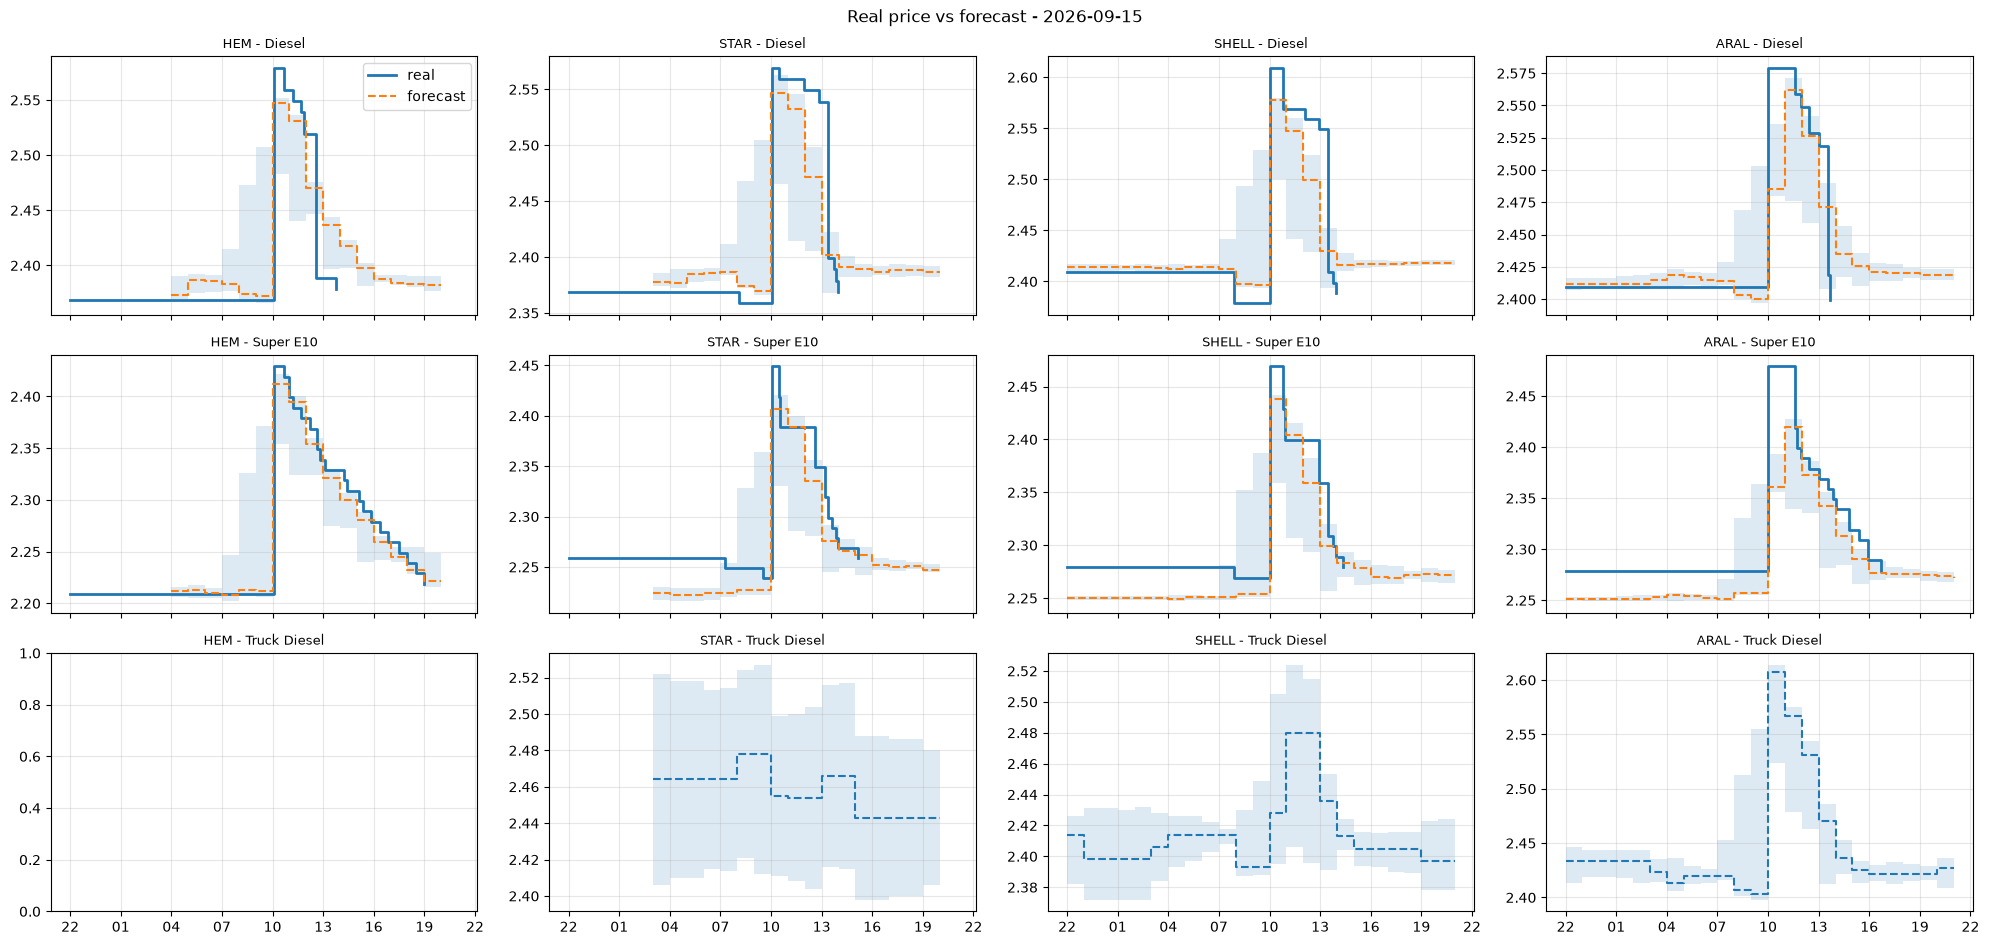

In [14]:
DAY = pd.Timestamp("2026-09-15").date()   # any day within the forecast data
d0 = pd.Timestamp(DAY, tz="Europe/Berlin"); d1 = d0 + pd.Timedelta(days=1)
fcd = fc[(fc.target_ts_berlin>=d0)&(fc.target_ts_berlin<d1)]
# for each target keep the latest forecast fetched before the target
fcd = fcd[fcd.retrieved_at_berlin <= fcd.target_ts_berlin].sort_values("retrieved_at_berlin").groupby(["station","fuel","target_ts_berlin"]).tail(1)

stations, fuels = list(UUIDS), sorted(fc.fuel.unique())
fig, axs = plt.subplots(len(fuels), len(stations), figsize=(5*len(stations), 3.2*len(fuels)), sharex=True, squeeze=False)
for i, f in enumerate(fuels):
    for j, s in enumerate(stations):
        ax = axs[i,j]
        r = clean[(clean.station==s)&(clean.fuel==f)&(clean.ts>=d0-pd.Timedelta(days=1))&(clean.ts<d1)].sort_values("ts")
        if len(r):
            prev = r[r.ts<d0].tail(1); r = pd.concat([prev.assign(ts=d0), r[r.ts>=d0]])
            ax.step(r.ts, r.price, where="post", label="real", lw=2)
        p = fcd[(fcd.station==s)&(fcd.fuel==f)].sort_values("target_ts_berlin")
        if len(p):
            ax.step(p.target_ts_berlin, p.price, where="post", label="forecast", ls="--")
            ax.fill_between(p.target_ts_berlin, p.min_price, p.max_price, step="post", alpha=.15)
        ax.set_title(f"{s} - {f}", fontsize=9); ax.grid(alpha=.3)
        ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H"))
axs[0,0].legend(); plt.suptitle(f"Real price vs forecast - {DAY}"); plt.tight_layout(); plt.show()

## 5. How can we judge the deviation? (alternatives + proposed solution)
The time-frame problem: the real price is a **step function** (changes at irregular moments), while the forecast comes at **discrete time points** with different **horizons** (how long before the target it was fetched).

| Alternative | Idea | Weakness |
|---|---|---|
| 1. Compare only at real price-change moments | error at each change | ignores how long a price lasts; says nothing for periods without change |
| 2. Compare at forecast points (real price forward-filled to the target) | MAE/RMSE/bias at each target | points can be sparse/uneven |
| 3. **Time-weighted error**: treat real and forecast as step functions, integrate \|real - forecast\| over time | every minute counts equally | slightly more complex |
| 4. Relative error (MAPE) | comparable across fuels | little benefit here, prices are similar in size |

**Proposed solution:** (3), a time-weighted MAE on a 5-minute grid, plus the **signed bias** (forecast - real) to see over/under-prediction, broken down by **horizon**.

## 6. Deviation by hour

In [15]:
# real = step (5-min grid). Forecast as steps: for each target keep the latest version before the target, then ffill onto the grid
f_last = fc[fc.retrieved_at_berlin <= fc.target_ts_berlin].sort_values("retrieved_at_berlin") \
           .groupby(["station","fuel","target_ts_berlin"]).tail(1)
def fc_grid(g):
    s = g.set_index("target_ts_berlin").price; s = s[~s.index.duplicated(keep="last")].sort_index()
    return s.reindex(s.index.union(grid)).ffill().reindex(grid)
fcs = (pd.concat({key: fc_grid(g) for key, g in f_last.groupby(["station", "fuel"])},
                 names=["station", "fuel", "ts"])
         .rename("fc").reset_index())
cmp_ = step.merge(fcs, on=["station","fuel","ts"], how="inner").dropna(subset=["price","fc"])
cmp_["err"] = cmp_.fc - cmp_.price
cmp_["abs_err"] = cmp_.err.abs()
print("MAE total (cent):", round(cmp_.abs_err.mean()*100,2), "| bias:", round(cmp_.err.mean()*100,2))
display(cmp_.groupby(["station","fuel"])[["abs_err","err"]].mean().mul(100).round(2))

MAE total (cent): 6.81 | bias: -4.52


abs_err   err
station fuel                    
ARAL    Diesel        7.67 -5.43
        Super E10     6.70 -4.41
HEM     Diesel        7.64 -5.38
        Super E10     6.12 -4.24
SHELL   Diesel        7.87 -5.48
        Super E10     6.30 -3.87
STAR    Diesel        6.84 -4.31
        Super E10     5.37 -3.06

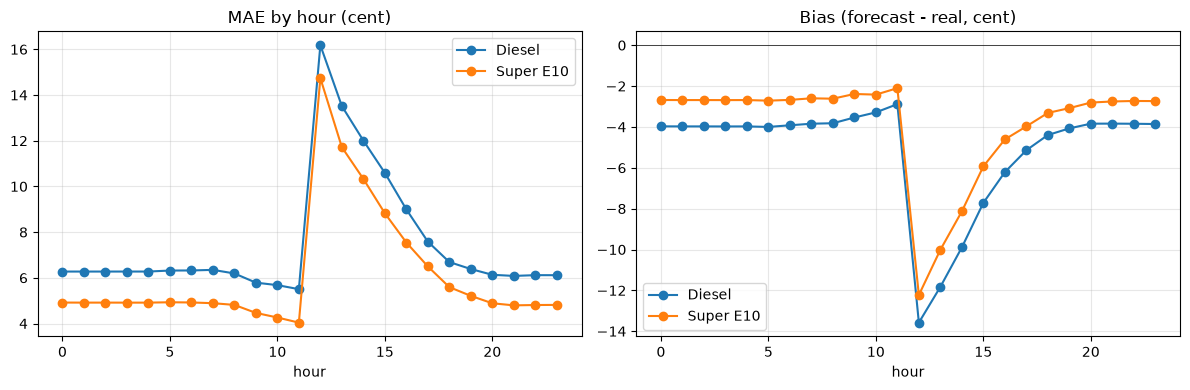

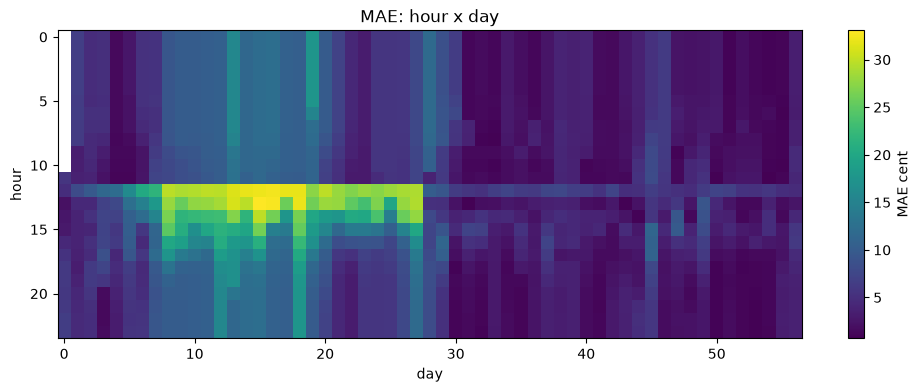

In [16]:
# Deviation by hour of day (MAE and bias) - is there a pattern?
by_h = cmp_.groupby(["fuel","hour"]).agg(MAE=("abs_err","mean"), bias=("err","mean")).mul(100).reset_index()
fig, axs = plt.subplots(1,2, figsize=(12,4))
for f, g in by_h.groupby("fuel"):
    axs[0].plot(g.hour, g.MAE, marker="o", label=f); axs[1].plot(g.hour, g.bias, marker="o", label=f)
axs[0].set_title("MAE by hour (cent)"); axs[1].set_title("Bias (forecast - real, cent)")
for a in axs: a.set_xlabel("hour"); a.grid(alpha=.3); a.legend()
axs[1].axhline(0, c="k", lw=.5); plt.tight_layout(); plt.show()
# Deviation over time (hour x date)
h = cmp_.groupby(["date","hour"]).abs_err.mean().mul(100).unstack().T
plt.figure(figsize=(12,4)); plt.imshow(h, aspect="auto", cmap="viridis"); plt.colorbar(label="MAE cent")
plt.ylabel("hour"); plt.xlabel("day"); plt.title("MAE: hour x day"); plt.show()

/tmp/ipykernel_1783205/2679682030.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  hz.groupby(pd.cut(hz.horizon_h,[0,1,3,6,12,24,48,1e9])).abs_err.mean().plot.bar(title="MAE (cent) by horizon"); plt.show()


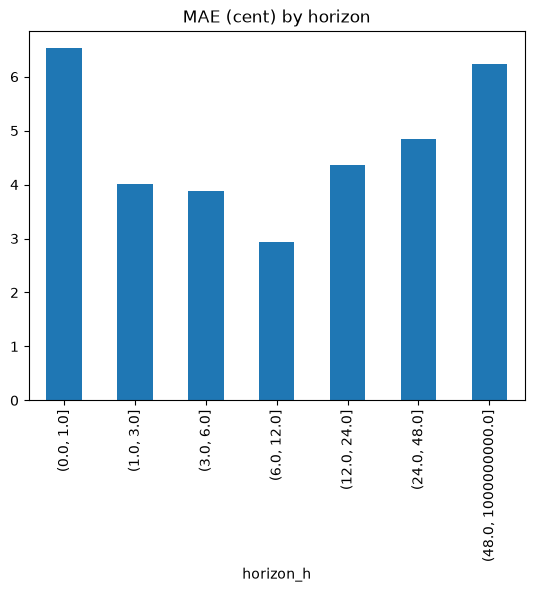

In [17]:
# By forecast horizon (how far ahead)
hz = fc.merge(step[["station","fuel","ts","price"]], left_on=["station","fuel","target_ts_berlin"], right_on=["station","fuel","ts"])
hz["abs_err"] = (hz.price_x - hz.price_y).abs()*100
hz.groupby(pd.cut(hz.horizon_h,[0,1,3,6,12,24,48,1e9])).abs_err.mean().plot.bar(title="MAE (cent) by horizon"); plt.show()

## 7. Bonus (own choice)
Idea: compare the forecast with a simple **baseline** ("yesterday's price at the same time") and check whether the incs forecast is actually better.

In [18]:
naive = step[["station","fuel","ts","price"]].copy(); naive["ts"] += pd.Timedelta(days=1); naive = naive.rename(columns={"price":"naive"})
b = cmp_.merge(naive, on=["station","fuel","ts"]).dropna(subset=["naive"])
print("MAE forecast :", round((b.fc-b.price).abs().mean()*100,2), "cent")
print("MAE yesterday:", round((b.naive-b.price).abs().mean()*100,2), "cent")

/tmp/ipykernel_1783205/2795136014.py:1: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  naive = step[["station","fuel","ts","price"]].copy(); naive["ts"] += pd.Timedelta(days=1); naive = naive.rename(columns={"price":"naive"})


MAE forecast : 6.81 cent
MAE yesterday: 2.79 cent
